In [1]:
import pandas as pd
import numpy as np



In [2]:
df = pd.read_csv("../data/PRSA_Data_Aotizhongxin_20130301-20170228.csv")

df["timestamp"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("timestamp").reset_index(drop=True)

print("Toplam satır:", len(df))
print(df[["timestamp", "PM2.5"]].head())


Toplam satır: 35064
            timestamp  PM2.5
0 2013-03-01 00:00:00    4.0
1 2013-03-01 01:00:00    8.0
2 2013-03-01 02:00:00    7.0
3 2013-03-01 03:00:00    6.0
4 2013-03-01 04:00:00    3.0


In [3]:

df["next_timestamp"] = df["timestamp"].shift(-1)
df["target_pm25_next_hour"] = df["PM2.5"].shift(-1)


one_hour_later = (
    df["next_timestamp"] - df["timestamp"] == pd.Timedelta(hours=1)
)


valid_pairs = df[
    one_hour_later
    & df["PM2.5"].notna()
    & df["target_pm25_next_hour"].notna()
].copy()

print("Geçerli saat çifti:", len(valid_pairs))
print(valid_pairs[["timestamp", "PM2.5", "target_pm25_next_hour"]].head())


Geçerli saat çifti: 33929
            timestamp  PM2.5  target_pm25_next_hour
0 2013-03-01 00:00:00    4.0                    8.0
1 2013-03-01 01:00:00    8.0                    7.0
2 2013-03-01 02:00:00    7.0                    6.0
3 2013-03-01 03:00:00    6.0                    3.0
4 2013-03-01 04:00:00    3.0                    5.0


In [4]:
def naive_forecast(current_pm25):
    return current_pm25

valid_pairs["prediction"] = naive_forecast(valid_pairs["PM2.5"])

valid_pairs["absolute_error"] = abs(
    valid_pairs["target_pm25_next_hour"] - valid_pairs["prediction"]
)

print(valid_pairs[[
    "timestamp", "PM2.5", "target_pm25_next_hour", "prediction", "absolute_error"
]].head(10))


            timestamp  PM2.5  target_pm25_next_hour  prediction  \
0 2013-03-01 00:00:00    4.0                    8.0         4.0   
1 2013-03-01 01:00:00    8.0                    7.0         8.0   
2 2013-03-01 02:00:00    7.0                    6.0         7.0   
3 2013-03-01 03:00:00    6.0                    3.0         6.0   
4 2013-03-01 04:00:00    3.0                    5.0         3.0   
5 2013-03-01 05:00:00    5.0                    3.0         5.0   
6 2013-03-01 06:00:00    3.0                    3.0         3.0   
7 2013-03-01 07:00:00    3.0                    3.0         3.0   
8 2013-03-01 08:00:00    3.0                    3.0         3.0   
9 2013-03-01 09:00:00    3.0                    3.0         3.0   

   absolute_error  
0             4.0  
1             1.0  
2             1.0  
3             3.0  
4             2.0  
5             2.0  
6             0.0  
7             0.0  
8             0.0  
9             0.0  


In [5]:
largest_errors = valid_pairs.sort_values(
    "absolute_error", ascending=False
).head(5)

print(largest_errors[[
    "timestamp", "PM2.5", "target_pm25_next_hour", "prediction", "absolute_error"
]])


                timestamp  PM2.5  target_pm25_next_hour  prediction  \
1834  2013-05-16 10:00:00  197.0                  665.0       197.0   
11536 2014-06-24 16:00:00    3.0                  463.0         3.0   
25777 2016-02-08 01:00:00  494.0                  898.0       494.0   
25776 2016-02-08 00:00:00  152.0                  494.0       152.0   
24106 2015-11-30 10:00:00  344.0                    3.0       344.0   

       absolute_error  
1834            468.0  
11536           460.0  
25777           404.0  
25776           342.0  
24106           341.0  


In [6]:
actual = valid_pairs["target_pm25_next_hour"].to_numpy()
predicted = valid_pairs["prediction"].to_numpy()

mae = np.mean(np.abs(actual - predicted))
rmse = np.sqrt(np.mean((actual - predicted) ** 2))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))


MAE: 10.63
RMSE: 20.29


In [7]:
actual_example = np.array([40, 60, 80])
predicted_example = np.array([45, 50, 90])

mae_example = np.mean(np.abs(actual_example - predicted_example))
rmse_example = np.sqrt(np.mean((actual_example - predicted_example) ** 2))

print("Örnek MAE:", round(mae_example, 2))
print("Örnek RMSE:", round(rmse_example, 2))


Örnek MAE: 8.33
Örnek RMSE: 8.66


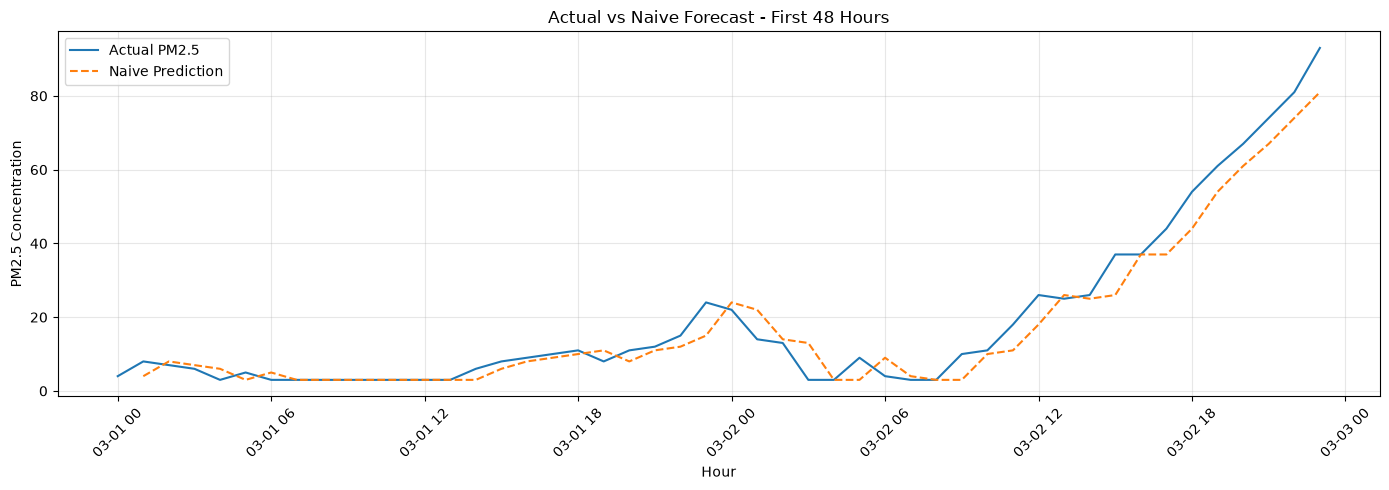

In [8]:
import matplotlib.pyplot as plt

# İlk 48 saat
hours = pd.date_range(
    start=df["timestamp"].min(),
    periods=48,
    freq="h"
)

actual_48 = (
    df.set_index("timestamp")["PM2.5"]
    .reindex(hours)
)

predicted_48 = (
    valid_pairs.set_index("next_timestamp")["prediction"]
    .reindex(hours)
)

plt.figure(figsize=(14, 5))

plt.plot(hours, actual_48, label="Actual PM2.5")
plt.plot(hours, predicted_48, label="Naive Prediction", linestyle="--")

plt.title("Actual vs Naive Forecast - First 48 Hours")
plt.xlabel("Hour")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

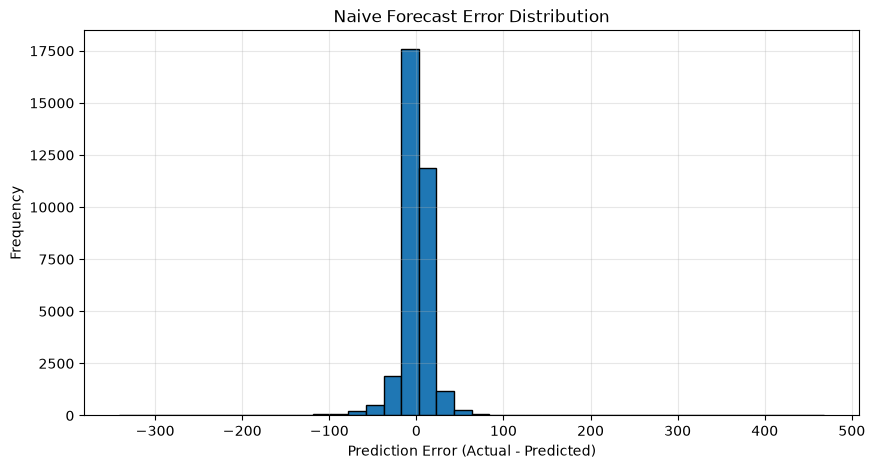

In [9]:
valid_pairs["error"] = (
    valid_pairs["target_pm25_next_hour"]
    - valid_pairs["prediction"]
)

plt.figure(figsize=(10, 5))

plt.hist(valid_pairs["error"], bins=40, edgecolor="black")

plt.title("Naive Forecast Error Distribution")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

1. Naive Forecast hangi dönemlerde iyi tahmin yapıyor?

PM2.5 değerlerinin çok fazla değişmediği, daha stabil dönemlerde iyi tahmin yapar. Çünkü mevcut saatin değerini bir sonraki saat için kullanır.

2. PM2.5 hızlı yükseldiğinde tahmin nasıl davranıyor?

Model önceki saatin değerini kullandığı için ani yükselişleri yakalayamaz ve gerçek değerden daha düşük tahmin üretir.

3. Ani düşüşlerde ne oluyor?

Model yine önceki saatin yüksek değerini kullanır. Bu nedenle gerçek değerden daha yüksek tahmin üretir.

4. Geçmiş saatin değerini kullanmak hangi sınırlamaya sahip?

Naive Forecast yalnızca son ölçüme dayanır. Hava koşullarını, geçmiş eğilimleri ve ani değişimlerin nedenlerini dikkate almaz. Bu yüzden hızlı değişimlerin olduğu dönemlerde hata oranı artabilir.